
## **IMPLEMENTASI METODE CLAHE**
### *(Contrast Limited Adaptive Histogram Equalization) PADA CITRA DIGITAL*

**Tugas Mata Kuliah:** Citra Digital

**Disusun oleh:**
- Nama: Shela Rahma Fitri
- NIM: 24260012
- Program Studi: teknik informatika
- Semester: 5


### **1. Pendahuluan**

Pada praktikum ini, metode **Contrast Limited Adaptive Histogram Equalization (CLAHE)** digunakan untuk meningkatkan kontras lokal pada citra digital. Metode ini bekerja dengan membagi gambar menjadi beberapa area kecil, melakukan pemerataan histogram pada setiap area, serta membatasi peningkatan kontras agar tidak berlebihan.

Pengolahan dilakukan menggunakan Python pada Jupyter Notebook dengan bantuan library OpenCV, NumPy, dan Matplotlib. Hasilnya akan dibandingkan dengan citra asli melalui tampilan gambar, histogram, dan perhitungan statistik intensitas piksel.



### **2. Tujuan Praktikum**

Tujuan dari praktikum ini adalah:

1. Memahami prinsip kerja metode CLAHE dalam meningkatkan kontras lokal citra digital.
2. Mengimplementasikan metode CLAHE menggunakan Python dan library OpenCV.
3. Memahami pengaruh parameter CLAHE terhadap hasil pengolahan citra.
4. Menganalisis perubahan citra melalui perbandingan visual, histogram, dan statistik intensitas piksel.


### **3. Library**

Library yang digunakan dalam program pengolahan citra digital ini terdiri dari:

1. **OpenCV (`cv2`)**  
   Digunakan untuk membaca citra digital, melakukan konversi ruang warna, serta menerapkan metode CLAHE untuk meningkatkan kontras lokal pada citra.

2. **NumPy (`numpy`)**  
   Digunakan untuk mengolah data piksel dalam bentuk array dan melakukan perhitungan numerik, seperti nilai minimum, maksimum, rata-rata, dan standar deviasi intensitas piksel.

3. **Matplotlib (`matplotlib.pyplot`)**  
   Digunakan untuk menampilkan citra asli dan citra hasil pengolahan, serta membuat grafik histogram untuk membandingkan distribusi intensitas piksel sebelum dan sesudah penerapan CLAHE.

In [15]:

# Import library yang dibutuhkan

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

print("Semua library berhasil diimpor!")


Semua library berhasil diimpor!



### **4. Membaca dan Memeriksa Citra**

Pada tahap ini, citra digital dibaca menggunakan OpenCV. Setelah citra berhasil dimuat, dilakukan pemeriksaan terhadap dimensi, tipe data, rentang nilai piksel, dan jumlah piksel. Pemeriksaan ini bertujuan untuk mengetahui karakteristik citra yang akan digunakan dalam proses pengolahan menggunakan metode CLAHE.


In [16]:

# Membaca citra digital
image = cv2.imread("foto/fotoPantai.jpg")

# Memeriksa apakah citra berhasil dibaca
if image is None:
    raise FileNotFoundError(
        "Citra tidak ditemukan. Periksa nama file dan lokasi foto."
    )

# Memeriksa karakteristik citra
tinggi, lebar, kanal = image.shape

print("Dimensi citra :", lebar, "x", tinggi, "piksel")
print("Jumlah kanal  :", kanal)
print("Tipe data     :", image.dtype)
print("Nilai minimum :", np.min(image))
print("Nilai maksimum:", np.max(image))
print("Jumlah piksel :", tinggi * lebar)


Dimensi citra : 960 x 1280 piksel
Jumlah kanal  : 3
Tipe data     : uint8
Nilai minimum : 0
Nilai maksimum: 255
Jumlah piksel : 1228800



### **Analisis Karakteristik Citra**

Berdasarkan hasil pemeriksaan menggunakan Python dan OpenCV, diperoleh karakteristik citra digital yang akan digunakan dalam proses pengolahan menggunakan metode CLAHE sebagai berikut.

| No. | Karakteristik | Hasil | Penjelasan |
|---|---|---|---|
| 1 | Dimensi citra | 960 × 1280 piksel | Citra memiliki lebar 960 piksel dan tinggi 1280 piksel. |
| 2 | Jumlah kanal warna | 3 kanal | Citra memiliki tiga kanal warna, yaitu Blue, Green, dan Red (BGR), sesuai format yang digunakan OpenCV. |
| 3 | Tipe data | `uint8` | Setiap nilai kanal piksel disimpan sebagai bilangan bulat 8-bit tanpa tanda, dengan rentang nilai 0–255. |
| 4 | Nilai piksel minimum | 0 | Nilai terendah yang ditemukan pada seluruh kanal citra adalah 0. |
| 5 | Nilai piksel maksimum | 255 | Nilai tertinggi yang ditemukan pada seluruh kanal citra adalah 255. |
| 6 | Jumlah piksel | 1.228.800 piksel | Diperoleh dari perkalian lebar dan tinggi citra, yaitu 960 × 1280. |

Berdasarkan hasil tersebut, citra memiliki resolusi 960 × 1280 piksel dengan tiga kanal warna dan tipe data `uint8`. Karakteristik ini sesuai untuk diproses menggunakan OpenCV. Selanjutnya, citra akan ditampilkan terlebih dahulu sebelum dilakukan peningkatan kontras menggunakan metode CLAHE.



### **5. Menampilkan Citra Asli**

Pada tahap ini, citra asli ditampilkan sebelum dilakukan pengolahan menggunakan metode CLAHE. OpenCV membaca citra dalam format warna BGR, sehingga perlu dikonversi menjadi RGB agar warna ditampilkan dengan benar menggunakan Matplotlib. Citra asli ini digunakan sebagai pembanding untuk mengevaluasi perubahan kontras setelah proses pengolahan.


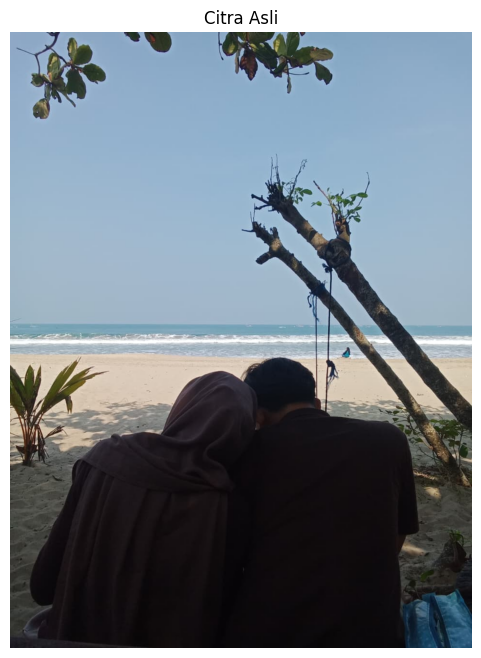

In [17]:

# Mengubah format warna BGR menjadi RGB
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Menampilkan citra asli
plt.figure(figsize=(7, 8))
plt.imshow(image_rgb)
plt.title("Citra Asli")
plt.axis("off")
plt.show()



### **6. Konversi Ruang Warna BGR ke LAB**

Sebelum menerapkan metode CLAHE, citra dikonversi dari ruang warna BGR ke LAB menggunakan fungsi `cv2.cvtColor()`. Ruang warna LAB terdiri dari tiga kanal, yaitu L (Lightness) yang merepresentasikan kecerahan, A yang merepresentasikan rentang warna hijau hingga merah, dan B yang merepresentasikan rentang warna biru hingga kuning.

Konversi ini dilakukan agar CLAHE dapat diterapkan pada kanal L saja, sedangkan kanal A dan B dipertahankan. Dengan demikian, peningkatan kontras dapat dilakukan tanpa mengolah setiap kanal warna secara terpisah.


In [18]:
# Mengonversi citra BGR menjadi LAB
image_lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)

# Memisahkan citra menjadi kanal L, A, dan B
L, A, B = cv2.split(image_lab)

# Menampilkan informasi citra
print("=== INFORMASI CITRA LAB ===")
print(f"Ukuran citra asli : {image.shape[1]} x {image.shape[0]} piksel")
print(f"Dimensi citra LAB : {image_lab.shape}")
print(f"Jumlah kanal      : {image_lab.shape[2]}")

# Menampilkan informasi masing-masing kanal
for nama, kanal in [("L (Lightness)", L), ("A (Hijau-Merah)", A), ("B (Biru-Kuning)", B)]:
    print(f"\nKanal {nama}")
    print(f"  Dimensi       : {kanal.shape}")
    print(f"  Tipe data     : {kanal.dtype}")
    print(f"  Nilai minimum : {np.min(kanal)}")
    print(f"  Nilai maksimum: {np.max(kanal)}")
    print(f"  Rata-rata     : {np.mean(kanal):.2f}")

=== INFORMASI CITRA LAB ===
Ukuran citra asli : 960 x 1280 piksel
Dimensi citra LAB : (1280, 960, 3)
Jumlah kanal      : 3

Kanal L (Lightness)
  Dimensi       : (1280, 960)
  Tipe data     : uint8
  Nilai minimum : 0
  Nilai maksimum: 255
  Rata-rata     : 114.86

Kanal A (Hijau-Merah)
  Dimensi       : (1280, 960)
  Tipe data     : uint8
  Nilai minimum : 102
  Nilai maksimum: 153
  Rata-rata     : 126.58

Kanal B (Biru-Kuning)
  Dimensi       : (1280, 960)
  Tipe data     : uint8
  Nilai minimum : 97
  Nilai maksimum: 168
  Rata-rata     : 121.59


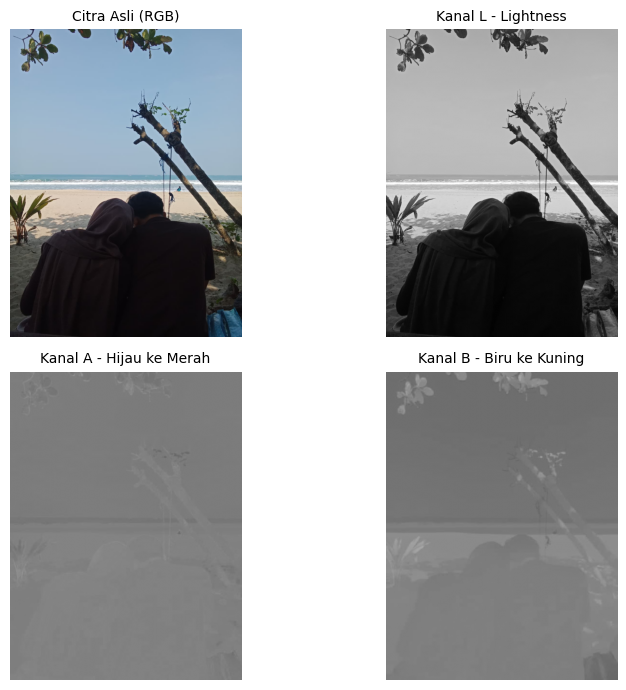

In [19]:
# Mengubah citra LAB menjadi tampilan RGB untuk gambar asli
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Menampilkan citra asli dan kanal LAB dalam ukuran lebih kecil
plt.figure(figsize=(9, 7))

plt.subplot(2, 2, 1)
plt.imshow(image_rgb)
plt.title("Citra Asli (RGB)", fontsize=10)
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(L, cmap="gray", vmin=0, vmax=255)
plt.title("Kanal L - Lightness", fontsize=10)
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(A, cmap="gray", vmin=0, vmax=255)
plt.title("Kanal A - Hijau ke Merah", fontsize=10)
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(B, cmap="gray", vmin=0, vmax=255)
plt.title("Kanal B - Biru ke Kuning", fontsize=10)
plt.axis("off")

plt.tight_layout()
plt.show()

### **Analisis Hasil Visualisasi Kanal LAB**

Berdasarkan hasil visualisasi, citra asli dan ketiga kanal LAB berhasil ditampilkan dengan baik. Citra asli memperlihatkan foto dua orang di tepi pantai, sedangkan kanal L, A, dan B menampilkan informasi yang berbeda dari citra tersebut.

Pada **kanal L (Lightness)**, gambar ditampilkan dalam bentuk grayscale untuk menunjukkan tingkat kecerahan setiap piksel. Area yang lebih terang menunjukkan nilai lightness yang lebih tinggi, sedangkan area yang lebih gelap menunjukkan nilai yang lebih rendah. Pada foto, bagian langit dan pantai terlihat relatif terang, sementara objek manusia dan pepohonan terlihat lebih gelap.

Pada **kanal A**, tingkat keabuan menunjukkan variasi nilai warna pada sumbu hijau hingga merah. Sementara itu, **kanal B** menunjukkan variasi nilai warna pada sumbu biru hingga kuning. Kedua kanal tersebut ditampilkan dalam bentuk grayscale agar perbedaan nilai pikselnya dapat diamati.

Dari hasil visualisasi, dapat diketahui bahwa konversi ruang warna LAB memisahkan informasi kecerahan pada kanal L dari informasi warna pada kanal A dan B. Oleh karena itu, kanal L akan digunakan pada tahap selanjutnya untuk penerapan metode CLAHE, sedangkan kanal A dan B dipertahankan untuk membantu menjaga informasi warna citra.

Pada tahap ini, citra belum mengalami peningkatan kontras karena proses yang dilakukan masih berupa konversi ruang warna dan pemisahan kanal.

### **7. Penerapan Metode CLAHE**

Contrast Limited Adaptive Histogram Equalization (CLAHE) merupakan metode pengolahan citra yang digunakan untuk meningkatkan kontras lokal. Berbeda dengan pemerataan histogram biasa yang memproses citra secara keseluruhan, CLAHE membagi citra menjadi beberapa area kecil yang disebut tile, kemudian melakukan pemerataan histogram pada setiap area.

CLAHE memiliki mekanisme pembatasan kontras (*contrast limiting*) untuk mengurangi peningkatan kontras yang berlebihan. Dengan demikian, detail pada area gelap maupun terang dapat terlihat lebih jelas tanpa meningkatkan kontras secara berlebihan.

Pada praktikum ini, CLAHE diterapkan pada kanal L (Lightness) dari ruang warna LAB. Kanal L dipilih karena menyimpan informasi kecerahan citra, sedangkan kanal A dan B tetap dipertahankan untuk menjaga informasi warna. Hasil pengolahan disimpan dalam variabel baru bernama `L_clahe` agar dapat dibandingkan dengan kanal L sebelum pengolahan.

### *7.1 Penerapan CLAHE pada Kanal L*

Penerapan CLAHE dilakukan menggunakan fungsi `cv2.createCLAHE()` dari library OpenCV. Pada praktikum ini digunakan dua parameter, yaitu `clipLimit = 2.0` dan `tileGridSize = (8, 8)`.

Parameter `clipLimit` mengatur pembatasan kontras pada histogram lokal, sedangkan `tileGridSize` menentukan pembagian citra menjadi kisi yang terdiri dari 8 baris dan 8 kolom area.

Setelah objek CLAHE dibuat, fungsi `apply()` digunakan untuk memproses kanal L. Hasil pengolahan disimpan dalam variabel `L_clahe`, sehingga kanal L asli tetap tersedia untuk perbandingan.

In [20]:
# Membuat objek CLAHE
clip_limit = 2.0
tile_grid_size = (8, 8)

clahe = cv2.createCLAHE(
    clipLimit=clip_limit,
    tileGridSize=tile_grid_size
)

# Menerapkan CLAHE pada kanal L
L_clahe = clahe.apply(L)

print("Penerapan CLAHE berhasil!")
print("Parameter clipLimit   :", clip_limit)
print("Parameter tileGridSize:", tile_grid_size)
print("Dimensi kanal L asli  :", L.shape)
print("Dimensi kanal L hasil :", L_clahe.shape)

Penerapan CLAHE berhasil!
Parameter clipLimit   : 2.0
Parameter tileGridSize: (8, 8)
Dimensi kanal L asli  : (1280, 960)
Dimensi kanal L hasil : (1280, 960)


### **Visualisasi Hasil CLAHE**

Setelah metode CLAHE diterapkan pada kanal L, hasil pengolahan divisualisasikan untuk mengetahui perubahan tingkat kecerahan dan kontras pada citra. Visualisasi dilakukan dengan membandingkan kanal L sebelum pengolahan dengan kanal L setelah pengolahan.

Kedua citra ditampilkan dalam bentuk grayscale agar perbedaan distribusi intensitas piksel dapat diamati dengan lebih jelas. Kanal L sebelum CLAHE digunakan sebagai citra pembanding, sedangkan kanal L setelah CLAHE menunjukkan hasil peningkatan kontras lokal.

Melalui perbandingan ini, dapat diamati apakah detail pada area tertentu menjadi lebih jelas setelah proses CLAHE diterapkan.

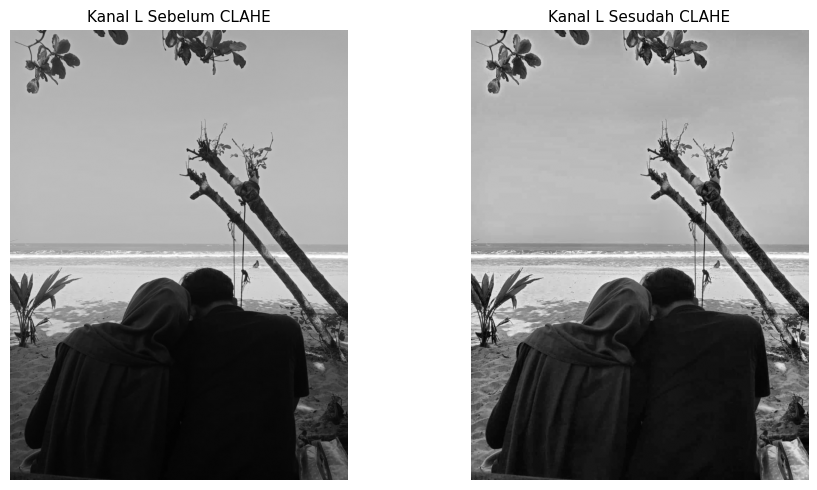

In [21]:
# Menampilkan perbandingan kanal L sebelum dan sesudah CLAHE
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(L, cmap="gray", vmin=0, vmax=255)
plt.title("Kanal L Sebelum CLAHE", fontsize=11)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(L_clahe, cmap="gray", vmin=0, vmax=255)
plt.title("Kanal L Sesudah CLAHE", fontsize=11)
plt.axis("off")

plt.tight_layout()
plt.show()

### **Menggabungkan Kanal LAB dan Menampilkan Hasil CLAHE**

Setelah proses CLAHE selesai, kanal L hasil pengolahan digabungkan kembali dengan kanal A dan B asli menggunakan fungsi `cv2.merge()`. Penggabungan ini bertujuan untuk membentuk kembali citra dalam ruang warna LAB dengan informasi kecerahan yang telah diproses.

Selanjutnya, citra dikonversi dari ruang warna LAB ke BGR menggunakan fungsi `cv2.cvtColor()`. Karena Matplotlib menggunakan format RGB untuk menampilkan gambar berwarna, citra kemudian dikonversi dari BGR ke RGB.

Hasil akhir ditampilkan berdampingan dengan citra asli untuk mengamati perubahan kontras lokal sekaligus mempertahankan tampilan warna foto.

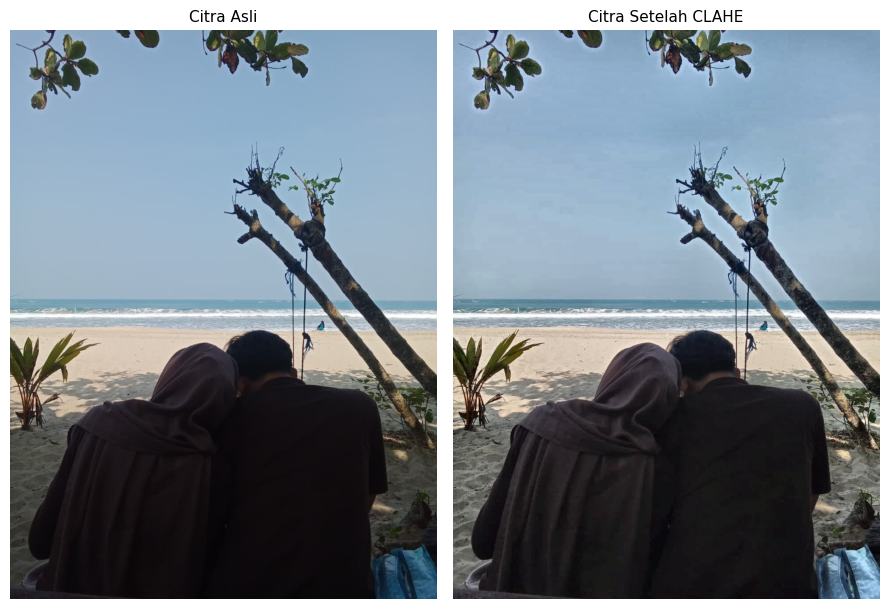

In [22]:
# Menggabungkan kanal L hasil CLAHE dengan kanal A dan B asli
lab_clahe = cv2.merge((L_clahe, A, B))

# Mengonversi LAB kembali ke BGR
image_clahe = cv2.cvtColor(lab_clahe, cv2.COLOR_LAB2BGR)

# Mengonversi BGR ke RGB untuk ditampilkan dengan Matplotlib
image_clahe_rgb = cv2.cvtColor(image_clahe, cv2.COLOR_BGR2RGB)

# Menampilkan perbandingan foto berwarna
plt.figure(figsize=(9, 6))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Citra Asli", fontsize=11)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image_clahe_rgb)
plt.title("Citra Setelah CLAHE", fontsize=11)
plt.axis("off")

plt.tight_layout()
plt.show()

### **Visualisasi Perubahan Intensitas Piksel**

Perbedaan visual antara citra asli dan citra hasil CLAHE terkadang sulit diamati secara langsung. Oleh karena itu, dilakukan analisis selisih intensitas piksel pada kanal L sebelum dan sesudah pengolahan.

Selisih absolut dihitung menggunakan fungsi `cv2.absdiff()`. Hasilnya menunjukkan besarnya perubahan nilai intensitas pada setiap piksel. Untuk memudahkan pengamatan, citra selisih dinormalisasi agar perbedaan yang kecil sekalipun dapat terlihat lebih jelas.

Visualisasi ini digunakan untuk menunjukkan lokasi perubahan intensitas, bukan sebagai citra hasil akhir CLAHE.

=== ANALISIS SELISIH INTENSITAS ===
Rata-rata selisih intensitas : 9.51
Selisih intensitas maksimum : 105
Jumlah piksel yang berubah  : 1139027
Total piksel                : 1228800
Persentase piksel berubah   : 92.69%


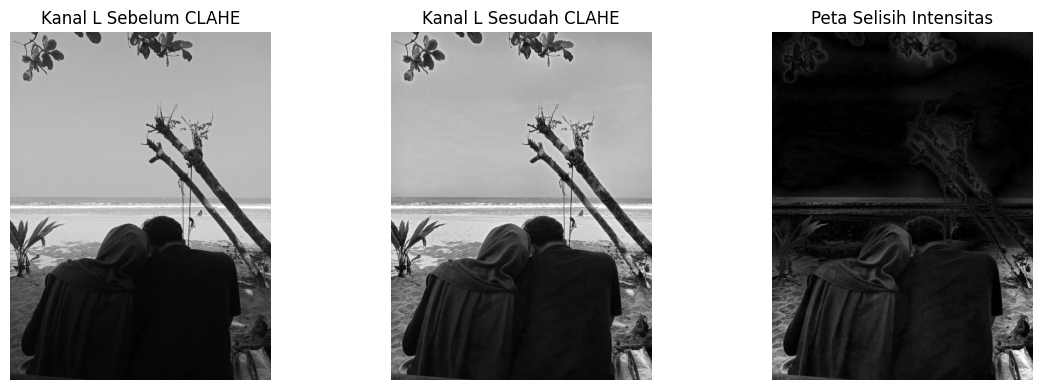

In [23]:
# Menghitung selisih absolut kanal L sebelum dan sesudah CLAHE
selisih = cv2.absdiff(L, L_clahe)

# Menormalisasi selisih agar lebih mudah diamati
selisih_normalisasi = cv2.normalize(
    selisih, None, 0, 255, cv2.NORM_MINMAX
)

# Menghitung statistik perubahan intensitas
print("=== ANALISIS SELISIH INTENSITAS ===")
print(f"Rata-rata selisih intensitas : {np.mean(selisih):.2f}")
print(f"Selisih intensitas maksimum : {np.max(selisih)}")
print(f"Jumlah piksel yang berubah  : {np.count_nonzero(selisih)}")
print(f"Total piksel                : {selisih.size}")
print(
    f"Persentase piksel berubah   : "
    f"{np.count_nonzero(selisih) / selisih.size * 100:.2f}%"
)

# Menampilkan kanal L asli, hasil CLAHE, dan peta selisih
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(L, cmap="gray", vmin=0, vmax=255)
plt.title("Kanal L Sebelum CLAHE")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(L_clahe, cmap="gray", vmin=0, vmax=255)
plt.title("Kanal L Sesudah CLAHE")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(selisih_normalisasi, cmap="gray", vmin=0, vmax=255)
plt.title("Peta Selisih Intensitas")
plt.axis("off")

plt.tight_layout()
plt.show()

### **Analisis Histogram Kanal L**

Histogram citra merupakan grafik yang menunjukkan distribusi frekuensi nilai intensitas piksel. Pada citra grayscale dengan tipe data 8-bit, nilai intensitas berkisar dari 0 hingga 255. Nilai 0 menunjukkan intensitas paling gelap, sedangkan nilai 255 menunjukkan intensitas paling terang.

Pada tahap ini, histogram kanal L sebelum dan sesudah CLAHE dibandingkan untuk mengetahui perubahan distribusi intensitas akibat pengolahan. Sumbu horizontal menunjukkan nilai intensitas piksel, sedangkan sumbu vertikal menunjukkan jumlah piksel pada setiap nilai intensitas.

Histogram sebelum CLAHE digunakan sebagai gambaran distribusi kecerahan awal, sedangkan histogram sesudah CLAHE digunakan untuk mengamati perubahan distribusi setelah peningkatan kontras lokal.

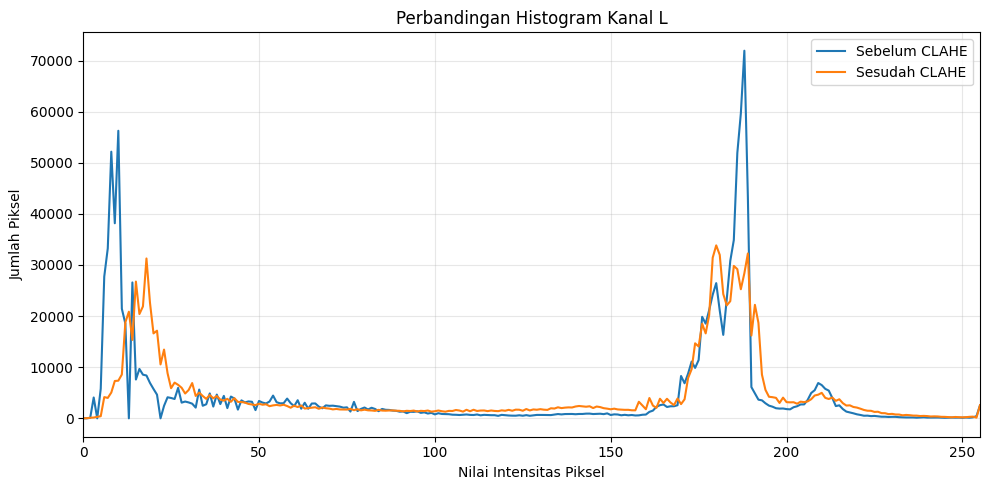

In [24]:
# Menghitung histogram kanal L sebelum dan sesudah CLAHE
hist_sebelum = cv2.calcHist([L], [0], None, [256], [0, 256])
hist_sesudah = cv2.calcHist([L_clahe], [0], None, [256], [0, 256])

# Membuat grafik histogram
plt.figure(figsize=(10, 5))

plt.plot(hist_sebelum, label="Sebelum CLAHE")
plt.plot(hist_sesudah, label="Sesudah CLAHE")

plt.title("Perbandingan Histogram Kanal L")
plt.xlabel("Nilai Intensitas Piksel")
plt.ylabel("Jumlah Piksel")
plt.xlim(0, 255)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### **Analisis Statistik Sebelum dan Sesudah CLAHE**

Analisis statistik dilakukan untuk mengetahui perubahan nilai intensitas kanal L setelah penerapan CLAHE. Parameter yang diamati meliputi nilai minimum, maksimum, rata-rata, dan standar deviasi.

Nilai minimum dan maksimum menunjukkan rentang intensitas piksel. Rata-rata menggambarkan tingkat kecerahan rata-rata, sedangkan standar deviasi menunjukkan tingkat penyebaran nilai intensitas piksel.

Hasil statistik sebelum dan sesudah pengolahan disajikan dalam bentuk tabel agar perbandingan dapat dilakukan dengan lebih mudah. Selisih nilai dihitung dengan mengurangkan nilai sebelum pengolahan dari nilai sesudah pengolahan.

In [25]:

# Menghitung statistik sebelum dan sesudah CLAHE
parameter = [
    "Nilai minimum",
    "Nilai maksimum",
    "Rata-rata intensitas",
    "Standar deviasi"
]

sebelum = [
    np.min(L),
    np.max(L),
    np.mean(L),
    np.std(L)
]

sesudah = [
    np.min(L_clahe),
    np.max(L_clahe),
    np.mean(L_clahe),
    np.std(L_clahe)
]

# Menyusun hasil ke dalam tabel
tabel = pd.DataFrame({
    "Parameter": parameter,
    "Sebelum CLAHE": sebelum,
    "Sesudah CLAHE": sesudah
})

tabel["Selisih"] = (
    tabel["Sesudah CLAHE"] - tabel["Sebelum CLAHE"]
)

# Membulatkan angka agar lebih mudah dibaca
kolom_numerik = ["Sebelum CLAHE", "Sesudah CLAHE", "Selisih"]
tabel[kolom_numerik] = tabel[kolom_numerik].round(2)

display(tabel)

,Parameter,Sebelum CLAHE,Sesudah CLAHE,Selisih
0,Nilai minimum,0.00,0.00,0.00
1,Nilai maksimum,255.00,255.00,0.00
2,Rata-rata intensitas,114.86,121.02,6.16
3,Standar deviasi,80.42,76.37,-4.06


### **Perhitungan Matematis Perubahan Intensitas**

Untuk mengetahui besarnya perubahan setelah CLAHE, dilakukan perhitungan selisih dan persentase perubahan nilai rata-rata serta standar deviasi.

Rumus selisih:

Selisih = Nilai sesudah − Nilai sebelum

Rumus persentase perubahan:

Persentase perubahan = (Selisih / Nilai sebelum) × 100%

Persentase perubahan digunakan untuk mengetahui seberapa besar nilai statistik berubah dibandingkan dengan kondisi awal. Interpretasi hasil tetap perlu mempertimbangkan visualisasi citra dan histogram karena perubahan statistik global tidak sepenuhnya menggambarkan kontras lokal.

In [26]:
# Menghitung perubahan rata-rata intensitas
mean_sebelum = np.mean(L)
mean_sesudah = np.mean(L_clahe)

selisih_mean = mean_sesudah - mean_sebelum
persen_mean = (selisih_mean / mean_sebelum) * 100

# Menghitung perubahan standar deviasi
std_sebelum = np.std(L)
std_sesudah = np.std(L_clahe)

selisih_std = std_sesudah - std_sebelum
persen_std = (selisih_std / std_sebelum) * 100

# Menampilkan hasil dalam tabel
hasil_perubahan = pd.DataFrame({
    "Parameter": ["Rata-rata intensitas", "Standar deviasi"],
    "Sebelum": [mean_sebelum, std_sebelum],
    "Sesudah": [mean_sesudah, std_sesudah],
    "Selisih": [selisih_mean, selisih_std],
    "Perubahan (%)": [persen_mean, persen_std]
})

hasil_perubahan[
    ["Sebelum", "Sesudah", "Selisih", "Perubahan (%)"]
] = hasil_perubahan[
    ["Sebelum", "Sesudah", "Selisih", "Perubahan (%)"]
].round(2)

display(hasil_perubahan)

,Parameter,Sebelum,Sesudah,Selisih,Perubahan (%)
0,Rata-rata intensitas,114.86,121.02,6.16,5.36
1,Standar deviasi,80.42,76.37,-4.06,-5.04


### **8. Kesimpulan**

Berdasarkan praktikum pengolahan citra digital menggunakan metode Contrast Limited Adaptive Histogram Equalization (CLAHE), dapat disimpulkan bahwa:

1. Ruang warna LAB memisahkan informasi kecerahan pada kanal L dari informasi warna pada kanal A dan B. Pemisahan ini memungkinkan peningkatan kontras dilakukan dengan berfokus pada kanal kecerahan.

2. Metode CLAHE berhasil diterapkan pada kanal L menggunakan library OpenCV dengan parameter `clipLimit = 2.0` dan `tileGridSize = (8, 8)`. Proses tersebut menghasilkan kanal kecerahan baru tanpa mengubah dimensi citra.

3. Perbandingan citra sebelum dan sesudah CLAHE menunjukkan perubahan intensitas pada sejumlah bagian gambar. Besarnya perubahan dapat dianalisis melalui visualisasi citra, peta selisih intensitas, histogram, dan statistik kanal L.

4. Analisis statistik membantu menjelaskan perubahan nilai intensitas secara kuantitatif. Namun, perubahan rata-rata dan standar deviasi saja belum cukup untuk menentukan kualitas hasil, sehingga perlu dipertimbangkan bersama hasil visualisasi dan histogram.

Secara keseluruhan, praktikum ini menunjukkan bahwa CLAHE dapat digunakan untuk mengolah kontras lokal pada citra digital. Hasil pengolahan dipengaruhi oleh karakteristik citra dan parameter yang digunakan, sehingga evaluasi visual dan kuantitatif diperlukan untuk menilai hasilnya.